# 第9讲 SVM 辅助复现
所有必做证据已印在学习单中；本 Notebook 用于离线核查。数据不用于临床诊断或部署。运行后按 Q1–Q6 对照学习单的表与图。

In [1]:
from pathlib import Path
import importlib.util
import numpy as np, pandas as pd
from IPython.display import Image, display
ROOT=Path.cwd().parent if Path.cwd().name=='notebook' else Path.cwd()
spec=importlib.util.spec_from_file_location('lesson9',ROOT/'scripts'/'pbl-svm-margin-build.py')
lesson=importlib.util.module_from_spec(spec); spec.loader.exec_module(lesson)
# analyze() 加载本地数据、训练内缩放、固定拆分、重训所有候选、生成 B–D 表图。
a=lesson.analyze()
print(a['summary'])

{'samples': 310, 'features': 6, 'normal': 100, 'abnormal': 210, 'missing': 0, 'exact_duplicate_rows': 0, 'duplicate_feature_rows': 0, 'patient_identifier_available': False, 'train': 186, 'validation': 62, 'test': 62, 'source': 'https://archive.ics.uci.edu/dataset/212/vertebral%2Bcolumn', 'license': 'CC BY 4.0', 'source_sha256': '79cab246a0d4a1863c27095e30729aea5ce2b5e7241e5c01d7e31a55173cf6d2', 'documentation_notes': ['源页单位栏为空，不擅自添加单位。', '三分类与二分类文件为同一批记录，不合并为620条。', '存在负值和极端值；来源未提供合理范围，不把负值当缺失，不自动删除。', '未见重复整行不等于已证实患者独立；发布数据没有患者标识可进一步核查。'], 'pelvic_identity_max_abs_error': 0.010000000000005116}


## Q1
表 A2 的两条候选线都能分开六个样本：哪条更能容忍同样大小的扰动？表 A1 的脊柱变量能否直接套用这个结论？

核验本单元结果与学习单对应的表或图（表 A1、表 A2）；写下一项你原先的判断需要的限定。

In [2]:
display(pd.DataFrame(a['audit'])[['feature','min','max','train_sd']])
points=a['toy']
rows=[]
for name,w,b in [('a',np.array([1.,0.]),0.),('b',np.array([1.,0.]),-.8),('5a',np.array([5.,0.]),0.)]:
    distance=np.abs(points@w+b)/np.linalg.norm(w)
    rows.append({'边界':name,'最小距离':distance.min(),'最近样本':[['N1','N2','N3','P1','P2','P3'][i] for i in np.flatnonzero(np.isclose(distance,distance.min()))]})
display(pd.DataFrame(rows))

,feature,min,max,train_sd
0,骨盆入射角,26.15,129.83,17.591176
1,骨盆倾斜角,-6.55,49.43,10.226870
2,腰椎前凸角,14.00,125.74,18.804738
3,骶骨倾角,13.37,121.43,13.988525
4,骨盆半径,70.08,163.07,14.394387
5,滑脱程度,-11.06,418.54,41.689615


,边界,最小距离,最近样本
0,a,1.0,"[N2, N3, P1]"
1,b,0.2,[P1]
2,5a,1.0,"[N2, N3, P1]"


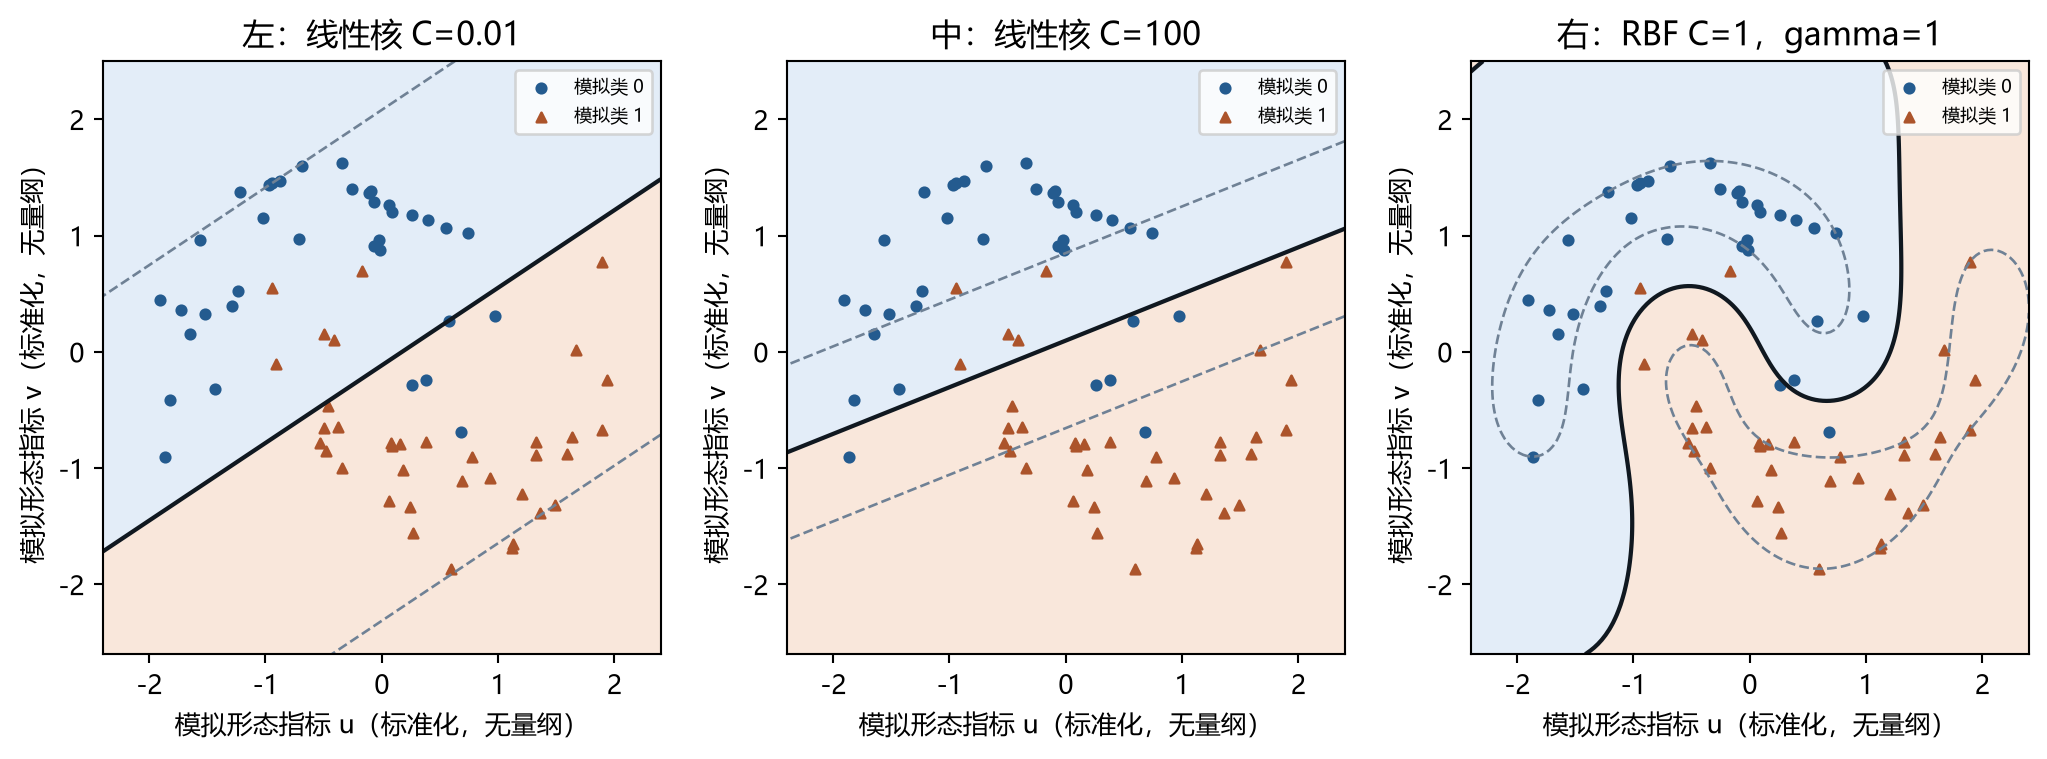

In [3]:
display(Image(filename=str(lesson.AS/'figure-s1.png')))

## Q2
表 B1 中移除不同样本后，边界为什么有时不变、有时移动？

核验本单元结果与学习单对应的表或图（表 A2、表 B1）；写下一项你原先的判断需要的限定。

In [4]:
# 表 B1 的三行 + 学习单 Q2③ 的核对（移除 P2）
display(pd.DataFrame(a['deletions']))

,operation,remaining,boundary_u,width,shown_in_worksheet,support_ids
0,全部保留,6,0.0,2.0,True,"N2,N3,P1"
1,移除 N1,5,0.0,2.0,True,"N2,N3,P1"
2,移除 P1,5,1.0,4.0,True,"N3,P3"
3,移除 P2,5,0.0,2.0,False,"N2,N3,P1"


## Q3
表 B2、图 B1 中改变 C，间隔宽度、违例与验证结果怎样变化？宽间隔能否直接支持“C 越小越好”？

核验本单元结果与学习单对应的表或图（图 S1、表 B2、图 B1）；写下一项你原先的判断需要的限定。

In [5]:
display(a['sim'][a['sim'].kernel=='linear'][['C','errors','violations','sv','width','validation_correct']])
m=np.array([1.4,.4,-.2,-1.])
display(pd.DataFrame({'带标签得分':m,'合页损失':np.maximum(0,1-m),'判对':m>0,'间隔违例':m<1}))

,C,errors,violations,sv,width,validation_correct
0,0.01,10,66,68,3.654793,22
1,1.00,11,21,24,1.427112,21
2,100.00,11,21,23,1.397112,21


,带标签得分,合页损失,判对,间隔违例
0,1.4,0.0,True,False
1,0.4,0.6,True,True
2,-0.2,1.2,False,True
3,-1.0,2.0,False,True


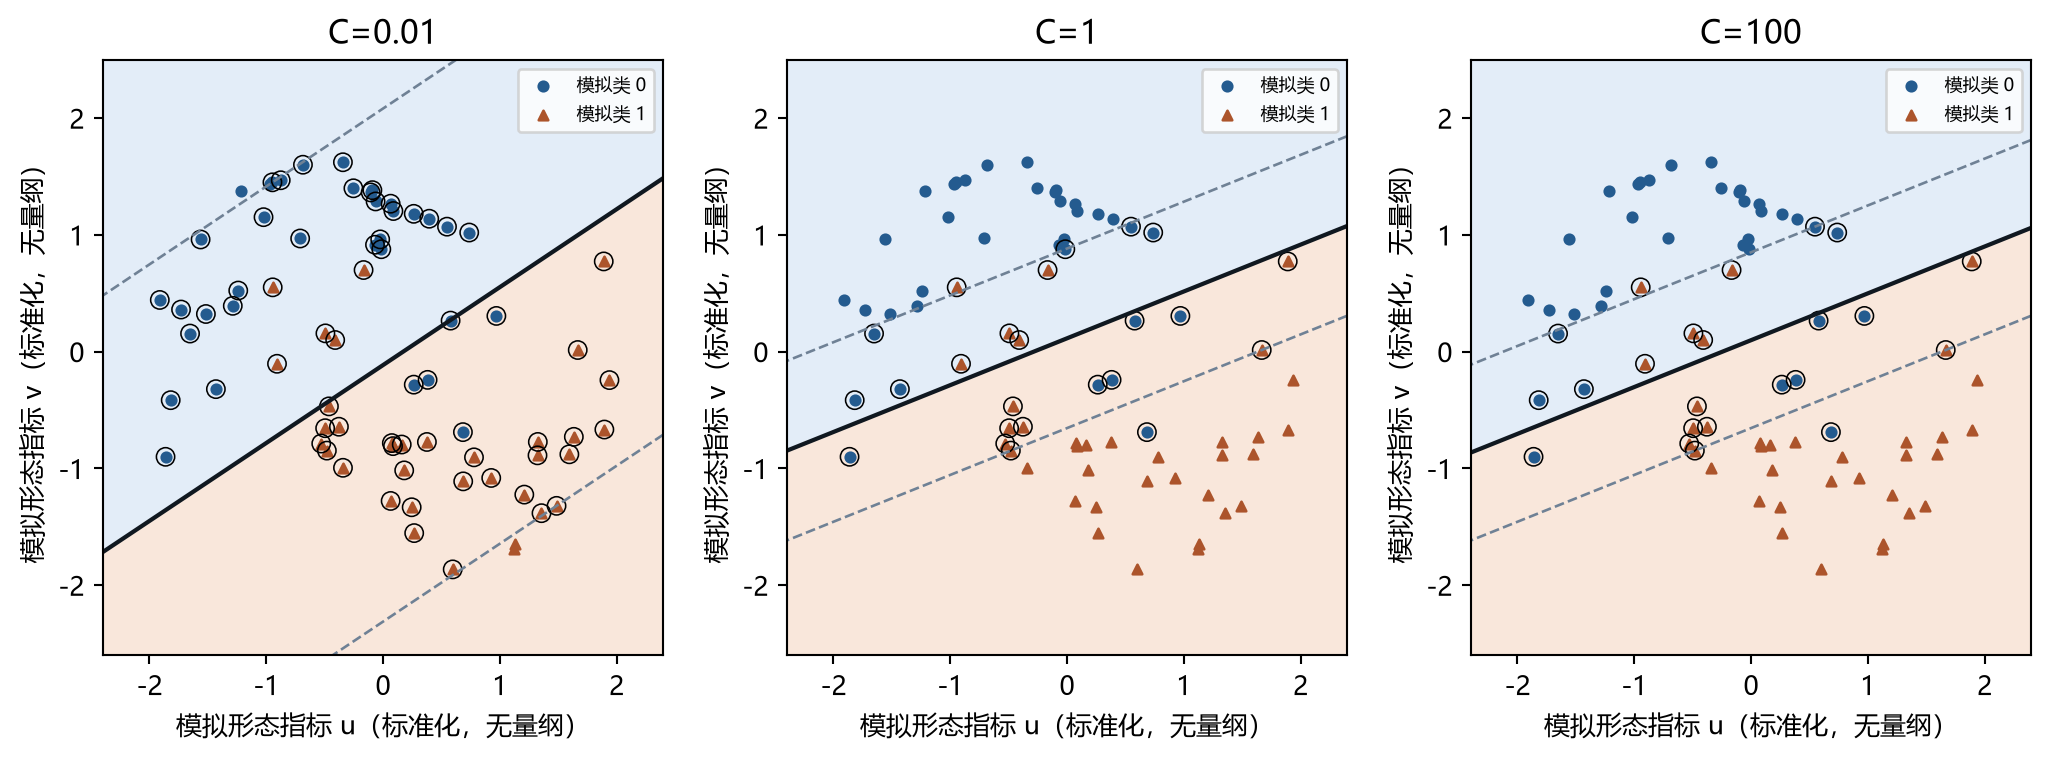

In [6]:
display(Image(filename=str(lesson.AS/'figure-b1.png')))

## Q4
图 C1、表 C1 中三种核怎样改变二维边界？二次核为什么不必显式升维？

核验本单元结果与学习单对应的表或图（图 C1、表 C1）；写下一项你原先的判断需要的限定。

In [7]:
display(a['sim'][(a['sim'].C==1)&(a['sim'].gamma==1)][['kernel','errors','sv','validation_correct']])
x=np.array([1.,2.]); z=np.array([2.,0.])
phi=lambda t: np.array([t[0]**2,np.sqrt(2)*t[0]*t[1],t[1]**2])
print('K=',(x@z)**2,' phi(x)·phi(z)=',phi(x)@phi(z))
print('RBF 相似度（距离1）：gamma=0.1 ->',np.exp(-.1),'；gamma=10 ->',np.exp(-10))

,kernel,errors,sv,validation_correct
1,linear,11,24,21
3,poly,8,23,21
4,rbf,4,29,23


K= 4.0  phi(x)·phi(z)= 4.0
RBF 相似度（距离1）：gamma=0.1 -> 0.9048374180359595 ；gamma=10 -> 4.5399929762484854e-05


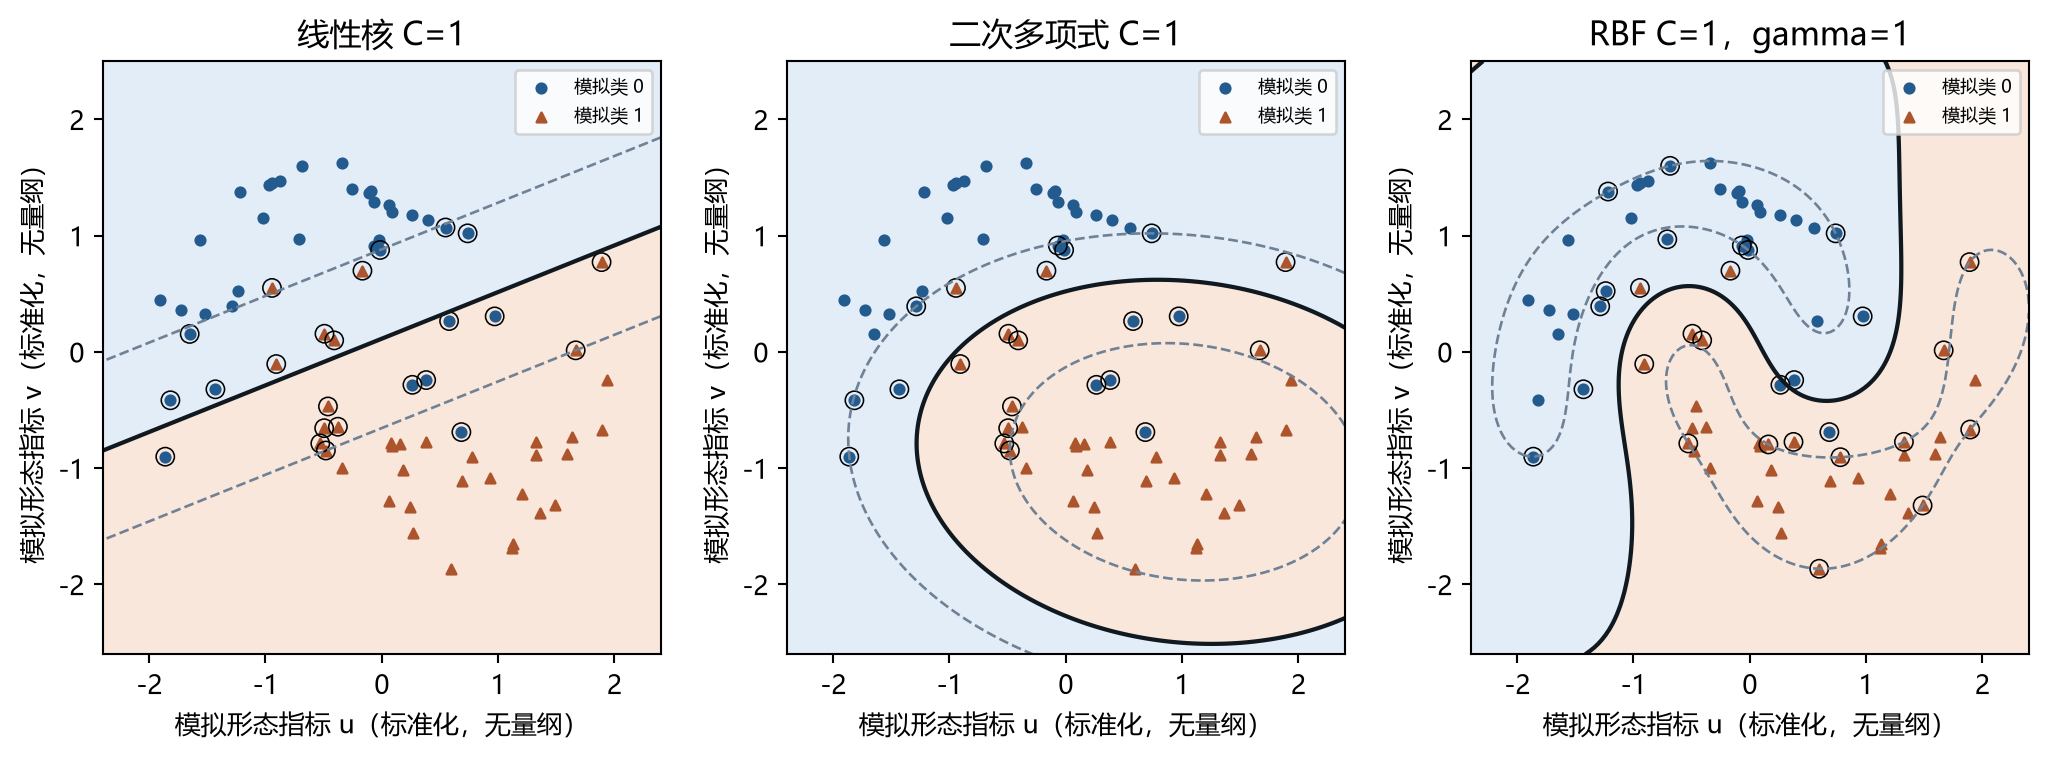

In [8]:
display(Image(filename=str(lesson.AS/'figure-c1.png')))

## Q5
表 C2、表 C3、图 C2 的脊柱验证结果足以冻结 L、P、R 中的哪一个？缩放、C 与 gamma 怎样改变判断？

核验本单元结果与学习单对应的表或图（表 S1、表 A1、表 C2、表 C3、图 C2）；写下一项你原先的判断需要的限定。

In [9]:
display(pd.DataFrame(a['best'])[['kernel','C','gamma','sv','train_ba','validation_ba','validation_tp','validation_tn']])
display(a['contrast'][['setting','width','sv','train_ba','validation_ba','validation_tn']])
display(a['grid'][a['grid'].kernel=='rbf'][['C','gamma','scaled','train_ba','validation_ba','sv']])

,kernel,C,gamma,sv,train_ba,validation_ba,validation_tp,validation_tn
0,linear,10.0,0.166667,56,0.865476,0.789286,39,13
1,poly,10.0,0.166667,56,0.913889,0.764286,39,12
2,rbf,10.0,0.010000,94,0.872619,0.790476,37,14


,setting,width,sv,train_ba,validation_ba,validation_tn
0,线性，C=0.01,6.689938,121,0.500000,0.500000,0
1,线性，C=0.1,1.192757,105,0.855556,0.778571,14
2,线性，C=10,0.351621,56,0.865476,0.789286,13
3,RBF，C=1，gamma=0.1，未标准化,NaN,186,1.000000,0.500000,0
4,RBF，C=1，gamma=0.1，已标准化,NaN,92,0.847619,0.766667,14
5,RBF，C=1，gamma=10，已标准化,NaN,186,0.991667,0.525000,1


,C,gamma,scaled,train_ba,validation_ba,sv
10,0.01,0.01,True,0.500000,0.500000,121
11,0.01,0.10,True,0.500000,0.500000,124
12,0.01,1.00,True,0.500000,0.500000,162
13,0.01,10.00,True,0.500000,0.500000,186
14,0.10,0.01,True,0.500000,0.500000,121
15,0.10,0.10,True,0.500000,0.500000,124
16,0.10,1.00,True,0.550000,0.500000,162
17,0.10,10.00,True,0.500000,0.500000,186
18,1.00,0.01,True,0.525397,0.550000,121
19,1.00,0.10,True,0.847619,0.766667,92


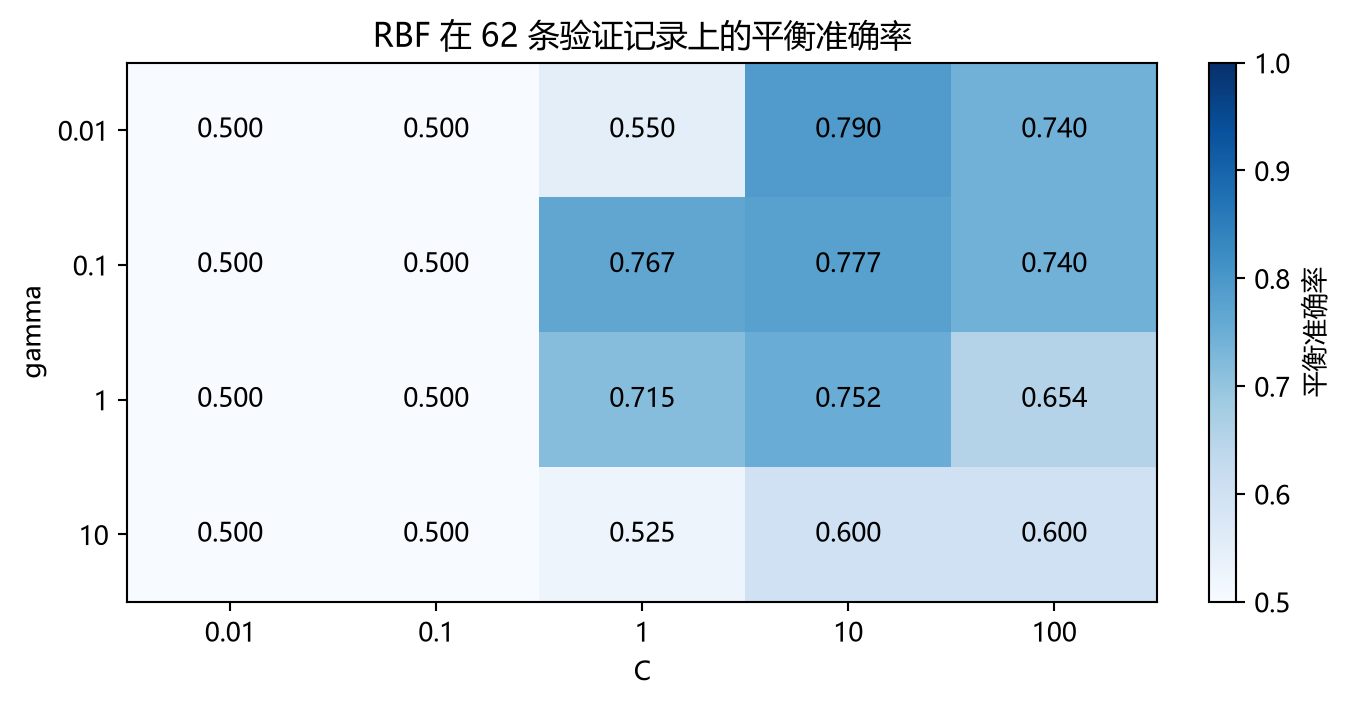

In [10]:
display(Image(filename=str(lesson.AS/'figure-c2.png')))

## Q6
表 D1、图 D1、表 D2：冻结方案能否保留？能迁移到哪些研究规模？

核验本单元结果与学习单对应的表或图（表 D1、图 D1、表 D2）；写下一项你原先的判断需要的限定。

In [11]:
display(a['test'])
display(a['stress'])
pd.testing.assert_frame_equal(pd.read_csv(lesson.AS/'packet-d-test.csv'),a['test'])

,kernel,errors,ba,tn,fp,fn,tp,sensitivity,specificity
0,linear,9,0.827381,15,5,4,38,0.904762,0.75
1,poly,10,0.789286,13,7,3,39,0.928571,0.65
2,rbf,8,0.839286,15,5,3,39,0.928571,0.75


,kernel,sd_fraction,mean_ba,sd_ba,flip,repetitions
0,linear,0.0,0.827381,1.110223e-16,0.000000,200
1,linear,0.1,0.830083,1.694149e-02,0.013790,200
2,linear,0.2,0.824762,2.089888e-02,0.021290,200
3,poly,0.0,0.789286,1.110223e-16,0.000000,200
4,poly,0.1,0.786851,9.973958e-03,0.009839,200
5,poly,0.2,0.783887,1.754888e-02,0.022339,200
6,rbf,0.0,0.839286,1.110223e-16,0.000000,200
7,rbf,0.1,0.830375,1.946164e-02,0.015323,200
8,rbf,0.2,0.815470,2.756730e-02,0.035081,200


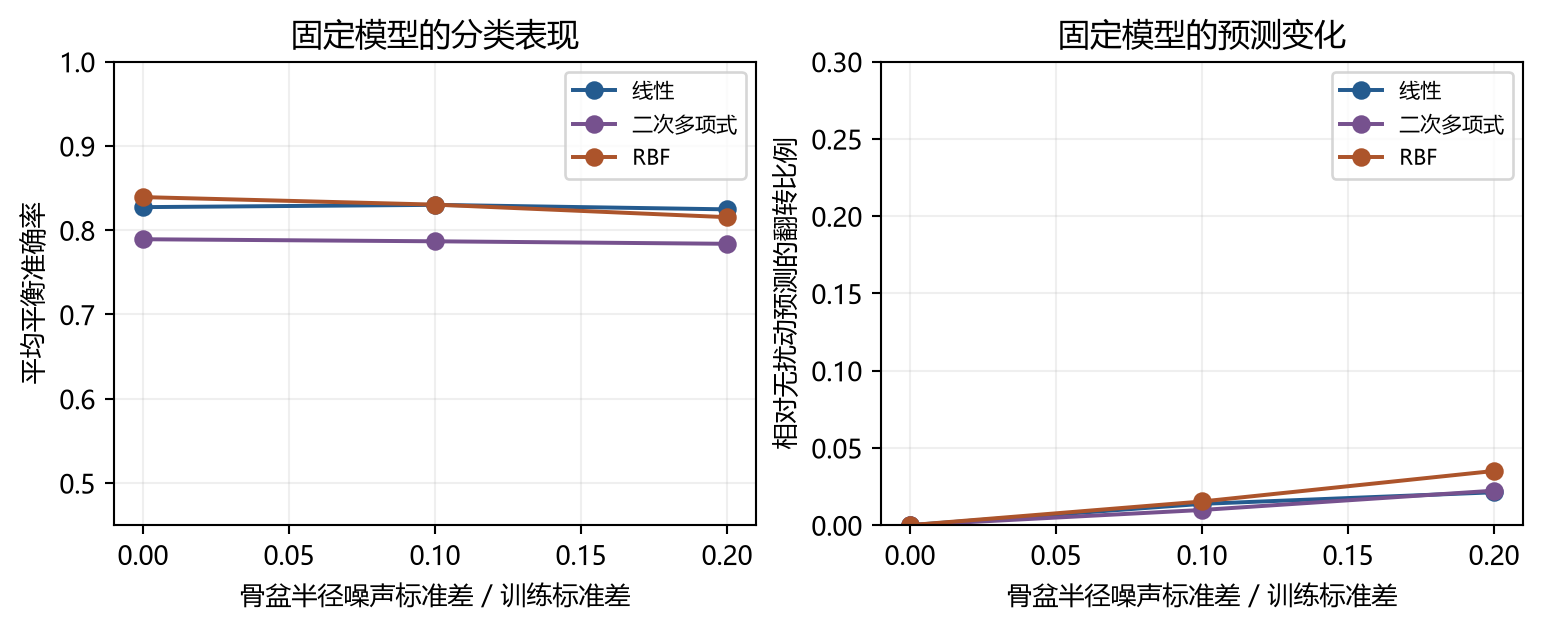

In [12]:
display(Image(filename=str(lesson.AS/'figure-d1.png')))

## 反思
1. 表 B2 与表 C3 中“最宽带宽”的表现为什么相反？这对选择 C 意味着什么？
2. 如果把表 D1 用来重新选核，会破坏哪一项比较规则？
3. 本数据没有受试者编号，这限制了哪一个结论？

## 可执行分析源码
下一单元展示本课分析函数的完整源码，检查只用训练集拟合缩放、验证集选参以及扰动试验共用同一批噪声。无需联网。

In [13]:
import inspect
print(inspect.getsource(lesson.analyze))

def analyze():
    AS.mkdir(parents=True,exist_ok=True); REVIEW.mkdir(exist_ok=True)
    raw=pd.read_csv(AS/'source-data'/'column_2C.dat',sep=r'\s+',header=None,names=FEATURES+['class'])
    raw3=pd.read_csv(AS/'source-data'/'column_3C.dat',sep=r'\s+',header=None,names=FEATURES+['class'])
    X=raw[FEATURES].to_numpy(); y=(raw['class']=='AB').to_numpy(dtype=int)
    assert raw.shape==(310,7) and raw.isna().sum().sum()==0
    assert np.array_equal(X,raw3[FEATURES].to_numpy())
    assert np.array_equal(y,(raw3['class']!='NO').to_numpy(dtype=int))
    ids=np.arange(310); dev,test=train_test_split(ids,test_size=.2,stratify=y,random_state=9)
    train,val=train_test_split(dev,test_size=.25,stratify=y[dev],random_state=9)
    pd.DataFrame({'row_id':ids+1,'split':np.select([np.isin(ids,train),np.isin(ids,val)],['train','validation'],default='test')}).to_csv(AS/'split.csv',index=False)
    raw.to_csv(AS/'vertebral-column.csv',index=False)
    audit=[]
    for j,n in enumerate(CN):
        audi